# VaR of Equity Portfolio

**FINM 36700 · Homework 3 · Group 22**
Lucas Albín Lazcano, Avi Rastogi, Mengting Wang, and Yihan Kong

_Acknowledgements: Claude Opus 5.5 was used to set up the submission structure as well as help with coding the solutions to the problems._

## Data

This problem uses `weekly` return data from `data/spx_returns_weekly.xlsx`.

Choose any `4` stocks to evaluate below.

We are using `AAPL`, `META`, `NVDA` and `TSLA`.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

tickers = ["AAPL", "META", "NVDA", "TSLA"]

rets = pd.read_excel("spx_returns_weekly.xlsx", sheet_name="spx returns").set_index("date")[tickers]
print(f"{rets.index[0]:%Y-%m-%d} to {rets.index[-1]:%Y-%m-%d}, {len(rets)} weeks, missing values: {rets.isna().sum().sum()}")
rets.head()

2015-07-10 to 2026-06-26, 573 weeks, missing values: 0


,AAPL,META,NVDA,TSLA
date,,,,
2015-07-10,-0.024991,0.007616,-0.032624,-0.074529
2015-07-17,0.051426,0.079820,0.016129,0.059849
2015-07-24,-0.039501,0.020851,-0.032364,-0.033680
2015-07-31,-0.025701,-0.030321,0.027269,0.002786
2015-08-07,-0.043341,0.003080,0.151804,-0.088822


# 1 Diversification

## 1.1

Using the full sample, calculate for each series the (unconditional)
* volatility
* empirical VaR (.05)
* empirical CVaR (.05)

Recall that by **empirical** we refer to the direct quantile estimation. (For example, using `.quantile()` in pandas.

In [22]:
def risk_stats(df, q=0.05):
    var = df.quantile(q)
    cvar = df[df <= var].mean()
    return pd.DataFrame({
        "Vol (ann.)": df.std() * np.sqrt(52),
        "VaR (.05)": var,
        "CVaR (.05)": cvar,
    })

stats_11 = risk_stats(rets)
stats_11.style.format("{:.2%}")

,Vol (ann.),VaR (.05),CVaR (.05)
AAPL,27.76%,-5.49%,-8.30%
META,35.75%,-7.23%,-10.64%
NVDA,45.44%,-8.58%,-11.53%
TSLA,57.97%,-11.70%,-14.78%


_Answer:_ TSLA is the riskiest of the four on every measure, with about 58% annualized vol, a weekly VaR of -11.70% and a CVaR of -14.78%. AAPL is the safest at about 28% vol and a VaR of -5.49%, and META and NVDA are in between. The ranking is the same for all three measures, so here vol, VaR and CVaR tell the same story. CVaR is always worse than VaR because it's the average of the weeks that are already past the VaR cutoff.

## 1.2

Form an equally-weighted portfolio of the investments.

Calculate the statistics of `1.1` for this portfolio, and compare the results to the individual return statistics. What do you find? What is driving this result?

In [23]:
rets["EW"] = rets[tickers].mean(axis=1)

stats_12 = risk_stats(rets)
stats_12.loc["Avg of the 4 stocks"] = stats_11.mean()
stats_12.style.format("{:.2%}")

,Vol (ann.),VaR (.05),CVaR (.05)
AAPL,27.76%,-5.49%,-8.30%
META,35.75%,-7.23%,-10.64%
NVDA,45.44%,-8.58%,-11.53%
TSLA,57.97%,-11.70%,-14.78%
EW,31.20%,-6.07%,-8.42%
Avg of the 4 stocks,41.73%,-8.25%,-11.31%


In [24]:
rets[tickers].corr().round(2)

,AAPL,META,NVDA,TSLA
AAPL,1.00,0.41,0.48,0.44
META,0.41,1.00,0.43,0.26
NVDA,0.48,0.43,1.00,0.41
TSLA,0.44,0.26,0.41,1.00


_Answer:_ The equally-weighted portfolio has 31.20% vol, a VaR of -6.07% and a CVaR of -8.42%. That's a lot better than the average stock (41.73% vol, -8.25% VaR, -11.31% CVaR) and better than META, NVDA and TSLA on their own. Only AAPL, the least risky stock, beats it.

This is diversification. The correlations between these stocks are only around 0.26 to 0.48, so their bad weeks don't all happen at the same time and some of the stock-specific moves cancel out. The risk doesn't go away completely, though. These are all big tech/growth names that tend to sell off together, so the portfolio is still a lot riskier than the overall market.

## 1.3

Re-calculate `1.2`, but this time drop your most volatile asset, and replace the portion it was getting with 0. (You could imagine we're replacing the most volatile asset with a negligibly small risk-free rate.)

In comparing the answer here to 1.2, how much risk is your most volatile asset adding to the portfolio? Is this in line with the amount of risk we measured in the stand-alone risk-assessment of `1.1`?

In [25]:
most_vol = stats_11["Vol (ann.)"].idxmax()
print("Most volatile asset:", most_vol)

# keep the 25% weights, the dropped stock's 25% just earns 0
ex_col = f"EW ex {most_vol}"
rets[ex_col] = rets[tickers].drop(columns=most_vol).sum(axis=1) / len(tickers)

stats_13 = risk_stats(rets[["EW", ex_col]])
stats_13.loc["% of EW risk removed"] = 1 - stats_13.loc[ex_col] / stats_13.loc["EW"]
stats_13.style.format("{:.2%}")

Most volatile asset: TSLA


,Vol (ann.),VaR (.05),CVaR (.05)
EW,31.20%,-6.07%,-8.42%
EW ex TSLA,21.69%,-4.23%,-6.00%
% of EW risk removed,30.49%,30.36%,28.72%


_Answer:_ TSLA is the most volatile stock. Replacing its 25% with a zero return brings portfolio vol down from 31.20% to 21.69%, VaR from -6.07% to -4.23%, and CVaR from -8.42% to -6.00%. So TSLA accounts for roughly 30% of the portfolio's risk on all three measures.

That's a lot, but it's less than the stand-alone numbers in 1.1 would suggest. If you just took TSLA's 58% vol times its 25% weight, you'd expect it to add about 14.5% of vol to the portfolio, but removing it only cuts about 9.5%. What matters for the portfolio is how TSLA moves with the other stocks, not just its own vol, and TSLA has the lowest correlations in the group (0.26 with META), so part of its risk was already being diversified away. Also, some of the drop here just comes from being 75% invested instead of 100%, since TSLA was replaced with cash instead of re-weighting the other three.

# 2. Dynamic Measures

## 2.1

Let's measure the **conditional** statistics of the equally-weighted portfolio of `1.2`, as of the end of the sample.

#### Volatility
For each security, calculate the **rolling** volatility series, $\sigma_t$, with a window of $m=26$.

The value at $\sigma_t$ in the notes denotes the estimate using data through time $t-1$, and thus (potentially) predicting the volatility at $\sigma_{t}$.

#### Mean
Suppose we can approximate that the weekly mean return is zero.

#### VaR
Calculate the **normal VaR** and **normal CVaR** for $q=.05$ and $\tau=1$ as of the end of the sample. Use the approximation, $\texttt{z}_{.05} = -1.65$.

#### Notation Note
In this setup, we are using a forecasted volatility, $\sigma_t$ to estimate the VaR return we would have estimated at the end of $t-1$ in prediction of time $t$.

#### Conclude and Compare
Report
* volatility (annualized).
* normal VaR (.05)
* normal CVaR (.05)

How do these compare to the answers in `1.2`?

Since the mean is assumed to be zero, we estimate vol as the square root of the average squared return. Both the rolling and expanding series are shifted by one week so that $\sigma_t$ only uses data through $t-1$. "As of the end of the sample" means the forecast for the week after the last date, so that one uses the last 26 weeks of data.

In [26]:
m = 26
z = -1.65
q = 0.05
cols = tickers + ["EW"]

# zero mean -> vol is the root of the average squared return
# shift(1) so sigma_t only uses data through t-1
roll_vol = np.sqrt((rets[cols] ** 2).rolling(m).mean()).shift(1)
exp_vol = np.sqrt((rets[cols] ** 2).expanding(m).mean()).shift(1)

# end of sample: forecast for next week using the last 26 weeks
sigma_end = np.sqrt((rets[cols].iloc[-m:] ** 2).mean())

cond = pd.DataFrame({
    "Vol (ann.)": sigma_end * np.sqrt(52),
    "Normal VaR (.05)": z * sigma_end,
    "Normal CVaR (.05)": -norm.pdf(z) / q * sigma_end,
})
cond.style.format("{:.2%}")

,Vol (ann.),Normal VaR (.05),Normal CVaR (.05)
AAPL,25.53%,-5.84%,-7.24%
META,41.24%,-9.44%,-11.70%
NVDA,30.65%,-7.01%,-8.69%
TSLA,37.26%,-8.53%,-10.57%
EW,24.23%,-5.55%,-6.87%


In [27]:
compare = pd.DataFrame({
    "Unconditional, empirical (1.2)": stats_12.loc["EW"].values,
    "Conditional, normal (2.1)": cond.loc["EW"].values,
}, index=["Vol (ann.)", "VaR (.05)", "CVaR (.05)"])
compare.style.format("{:.2%}")

,"Unconditional, empirical (1.2)","Conditional, normal (2.1)"
Vol (ann.),31.20%,24.23%
VaR (.05),-6.07%,-5.55%
CVaR (.05),-8.42%,-6.87%


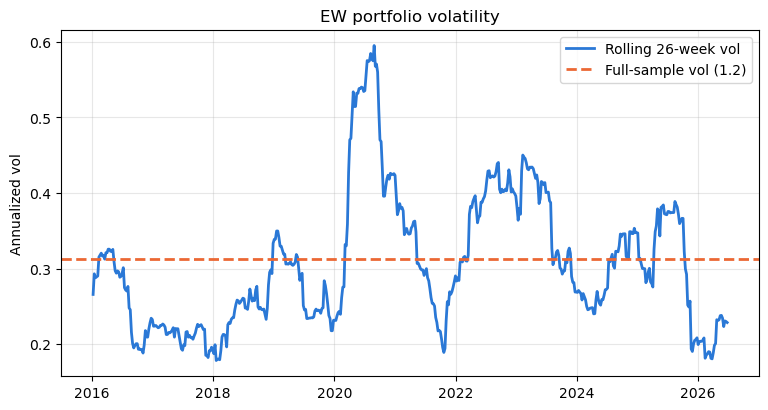

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(roll_vol.index, roll_vol["EW"] * np.sqrt(52), color="#2a78d6", lw=2, label="Rolling 26-week vol")
ax.axhline(stats_12.loc["EW", "Vol (ann.)"], color="#eb6834", lw=2, ls="--", label="Full-sample vol (1.2)")
ax.set_ylabel("Annualized vol")
ax.set_title("EW portfolio volatility")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

_Answer:_ At the end of the sample, the 26-week vol estimate for the EW portfolio is 24.23% annualized, which gives a normal VaR of -5.55% and a normal CVaR of -6.87%. All three are lower than the full-sample numbers from 1.2 (31.20% vol, -6.07% VaR, -8.42% CVaR).

So the last six months have been calmer than usual for these stocks. The full-sample numbers include rough periods like 2020 and 2022, while the rolling estimate only looks at recent weeks. The plot shows how much it moves around, from about 18% in early 2018 to almost 60% in 2020. It's also not the same for every stock: TSLA's recent vol (37%) is way below its full-sample 58%, while META's (41%) is actually higher than its full-sample 36%.

The CVaR gap is also partly from the normal assumption. Under the normal, CVaR is only about 1.24 times VaR, but in the actual data the EW portfolio's CVaR is about 1.39 times its VaR, so real returns have fatter tails and the normal CVaR probably understates how bad the worst weeks get.

## 2.2

Backtest the VaR using the **hit test**. Namely, check how many times the realized return at $t$ was smaller than the VaR return calculated using $\sigma_t$, (where again remember the notation in the notes uses $\sigma_t$ as a vol based on data through $t-1$.)

Report the percentage of "hits" using both the
* expanding volatility
* rolling volatility

In [29]:
var_exp = z * exp_vol["EW"]
var_roll = z * roll_vol["EW"]

hits = {}
for name, var in {"Expanding": var_exp, "Rolling": var_roll}.items():
    ok = var.notna()
    hit = rets.loc[ok, "EW"] < var[ok]
    hits[name] = {"Hits": hit.sum(), "Weeks": ok.sum(), "Hit rate": hit.mean()}

hits = pd.DataFrame(hits).T
hits.style.format({"Hits": "{:.0f}", "Weeks": "{:.0f}", "Hit rate": "{:.2%}"})

,Hits,Weeks,Hit rate
Expanding,22,547,4.02%
Rolling,21,547,3.84%


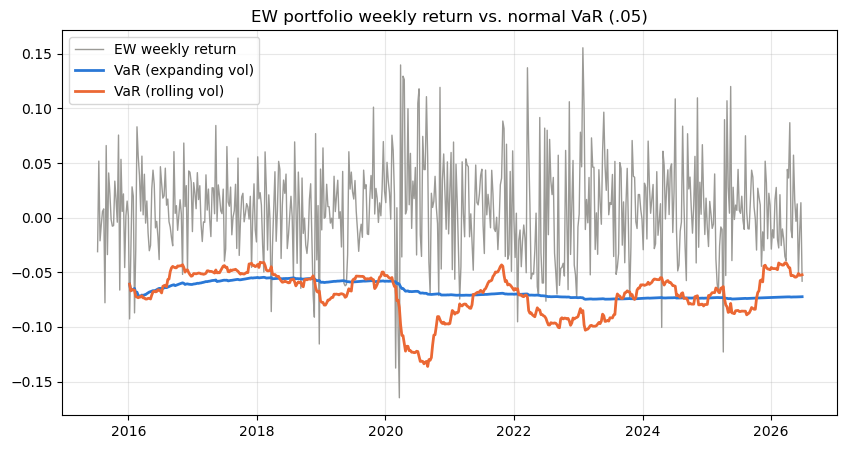

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rets.index, rets["EW"], color="#9b9a96", lw=1, label="EW weekly return")
ax.plot(var_exp.index, var_exp, color="#2a78d6", lw=2, label="VaR (expanding vol)")
ax.plot(var_roll.index, var_roll, color="#eb6834", lw=2, label="VaR (rolling vol)")
ax.set_title("EW portfolio weekly return vs. normal VaR (.05)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

_Answer:_ Both are a bit under the 5% target: 4.02% of weeks for expanding vol (22 out of 547) and 3.84% for rolling vol (21 out of 547). So on average both VaRs are slightly too conservative.

A big reason is the zero-mean assumption. These stocks went up a lot over the sample (the EW portfolio averaged about 0.75% a week), so assuming a zero mean puts the VaR too low and we get fewer hits than we should. Using squared returns around zero instead of around the actual mean also makes the vol estimate a little bigger.

The hit rates are close, but the two lines in the plot look very different. The expanding VaR is almost flat after the first couple of years, so it doesn't care whether we're in a calm or a volatile period. The rolling VaR moves with recent vol, which is what you want from a conditional risk measure. The problem with rolling is that it reacts late: after a very calm 2017, the rolling vol was down around 19%, and it got hit 6 times in 2018 once volatility came back. We'd still go with rolling since it actually reflects current risk, but neither one is perfect.